<div align="center">

Graph Neural Network on Protein–Protein Interaction Networks

**AI for BME 487**

Created by [Gopal Narayan Srivastava](www.linkedin.com/in/gopal-narayan-srivastava)
University of Michigan

[Google Scholar](https://scholar.google.com/citations?user=N_gpB7YAAAAJ&hl=en) • [GitHub](https://github.com/gnsrivastava) • [LinkedIn](www.linkedin.com/in/gopal-narayan-srivastava)

</div>

# Protein Function Prediction on the PPI Dataset using GCN and MLP

This notebook trains a **Graph Convolutional Network (GCN)** and a **Multi-Layer Perceptron (MLP)** to predict what proteins do, and compares them. It covers:

- **Data loading**: the PPI dataset from `torch_geometric.datasets`.
- **Why a graph should help**: checking that interacting proteins share functions.
- **Model training**: an MLP and a GCN with the same size and settings.
- **Evaluation**: micro-F1 on tissues the models have never seen.
- **Embedding visualisation with UMAP**.
- **Bonus**: a Graph Attention Network (GAT).

**The key idea.** Proteins work together in complexes and pathways. A protein's own 50 features say little about its function, but its interaction partners say a lot. An MLP looks at one protein at a time; a GCN also looks at the proteins it interacts with.

# Dataset

**PPI** (Zitnik & Leskovec, 2017) contains 24 protein–protein interaction networks, **one per human tissue**.

- **Nodes**: proteins (≈2,245 per tissue). Each protein has **50 features** (positional gene sets, motif gene sets, immunological signatures).
- **Edges**: interactions between proteins.
- **Labels**: **121 Gene Ontology (GO) terms**. A protein can have *several* functions, so each protein gets 121 yes/no answers (**multi-label**).
- **Split**: 20 tissues for training, 2 for validation and 2 for testing. The test tissues are **never seen** during training.

**Differences from the Cora demo**

| | PPI |
|---|---|
| Graphs | 24 (one per tissue) |
| Split | separate train / val / test graphs |
| Labels | any of 121 GO terms |
| Output | 121 sigmoids |
| Metric | micro-F1 |

**Install PyTorch and PyTorch Geometric**

In [ ]:
!pip install torch
!pip install torch-geometric
!pip install umap-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 28.4 MB/s eta 0:00:00


**Import Libraries**

In [1]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx
import umap

from torch_geometric.datasets import PPI
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.utils import to_networkx
from sklearn.metrics import f1_score

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using", device)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/python3.12/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Users/gopalsrivastava/miniconda/envs/erdos_ds_environment/lib/pytho

Using cpu


**Load the PPI dataset**

In [ ]:
train_dataset = PPI(root='/tmp/PPI', split='train')
val_dataset = PPI(root='/tmp/PPI', split='val')
test_dataset = PPI(root='/tmp/PPI', split='test')

# Each batch holds 2 whole tissue graphs
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=2)
test_loader = DataLoader(test_dataset, batch_size=2)

print("Train graphs:", len(train_dataset))
print("Validation graphs:", len(val_dataset))
print("Test graphs:", len(test_dataset))

Extracting /tmp/PPI/ppi.zip
Processing...


Train graphs: 20
Validation graphs: 2
Test graphs: 2


Done!


In [ ]:
data = train_dataset[0]   # one tissue graph
data

Data(x=[1767, 50], edge_index=[2, 32318], y=[1767, 121])

In [ ]:
train_dataset.print_summary('tsv')

PPI (#graphs=20):
          	  #nodes	  #edges
mean      	  2245.3	 61318.4
std       	   766.2	 28601.2
min       	   591  	  7708
quantile25	  1806  	 42288
median    	  2326  	 59862
quantile75	  2799.2	 85368.5
max       	  3480  	106754


In [ ]:
train_dataset.num_classes

121

In [ ]:
labels = data.y.numpy()   # shape: (number of proteins, 121)
print("Proteins in this tissue:", data.num_nodes)
print("Average interactions per protein:", round(data.num_edges / data.num_nodes, 1))
print("Average GO terms per protein:", round(labels.sum(axis=1).mean(), 1), "out of 121")

Proteins in this tissue: 1767
Average interactions per protein: 18.3
Average GO terms per protein: 36.8 out of 121


**Visualise part of one tissue network**

We pick one GO term and colour proteins orange if they have it. We draw a single well-connected protein and its direct partners.

Colouring by GO term 54


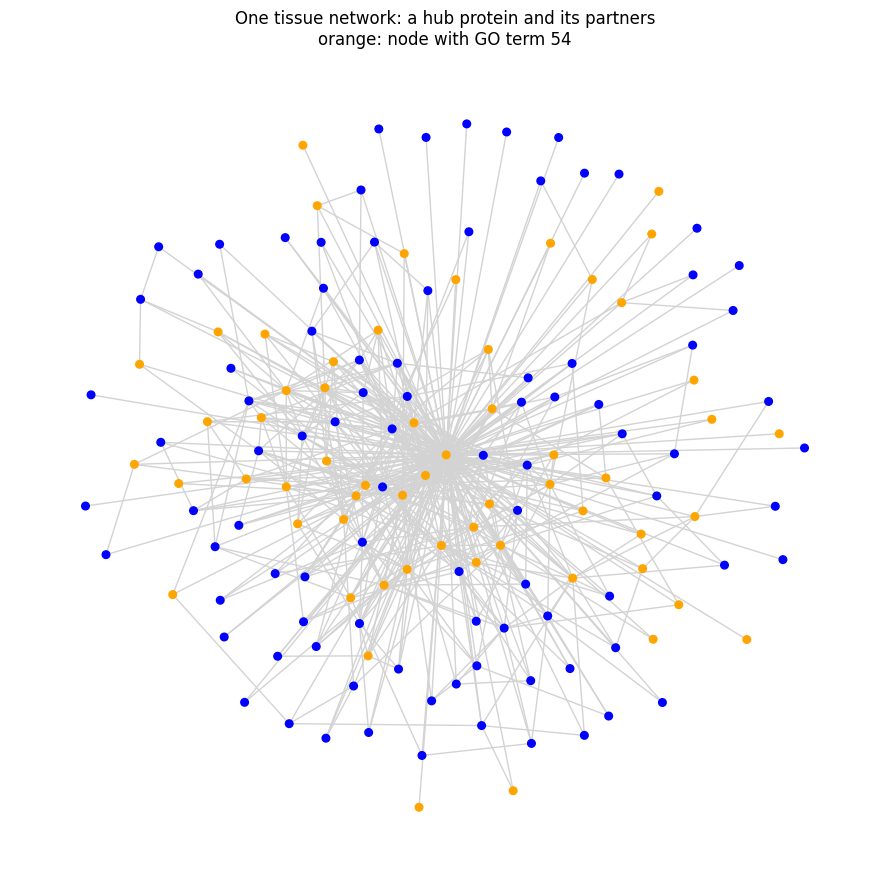

In [ ]:
# Pick a GO term that roughly 30% of proteins have, so both colours show up
go_term = int(np.argmin(np.abs(labels.mean(axis=0) - 0.3)))
print("Colouring by GO term", go_term)

G = to_networkx(data, to_undirected=True)
hub = max(G.degree, key=lambda pair: pair[1])[0]        # the protein with the most partners; returns node number
subset_nodes = [hub] + list(G.neighbors(hub))[:150]     #list(G.neighbors(hub)) returns 286
G_sub = G.subgraph(subset_nodes)

colors = ["orange" if labels[n, go_term] == 1 else "blue" for n in G_sub.nodes]
plt.figure(figsize=(9, 9))
plt.title(f"One tissue network: a hub protein and its partners\norange: node with GO term {go_term}")
nx.draw(G_sub, node_size=30, node_color=colors, edge_color="lightgray")
plt.tight_layout()
plt.show()

# Why should the graph help?

If interacting proteins share functions, then a protein's partners tell us something about the protein itself. For each GO term we compare:

- **Interacting pairs**: how often *both* proteins of an edge have the GO term.
- **Random pairs**: how often both proteins of a random pair have it.

Points above the dashed line mean interacting proteins share that function more than chance.

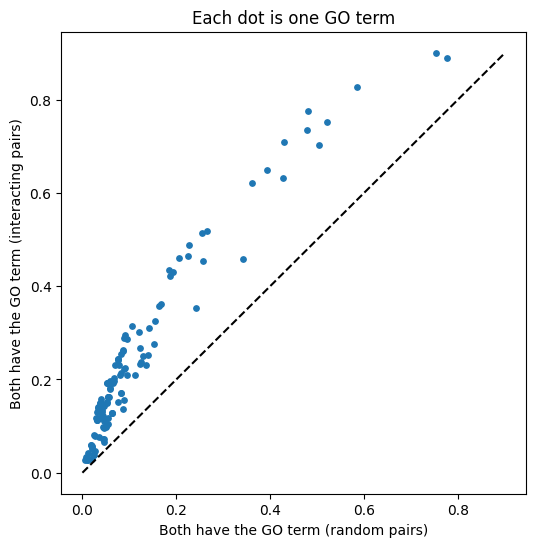

100% of GO terms are shared more often by interacting proteins


In [ ]:
src, dst = data.edge_index.numpy() # src: source node; dst: target node
rng = np.random.default_rng(0)
rand_src = rng.integers(0, data.num_nodes, len(src))
rand_dst = rng.integers(0, data.num_nodes, len(src))

both_connected = (labels[src] * labels[dst]).mean(axis=0)
both_random = (labels[rand_src] * labels[rand_dst]).mean(axis=0)

plt.figure(figsize=(6, 6))
plt.scatter(both_random, both_connected, s=15)
top = max(both_connected.max(), both_random.max())
plt.plot([0, top], [0, top], "k--")
plt.xlabel("Both have the GO term (random pairs)")
plt.ylabel("Both have the GO term (interacting pairs)")
plt.title("Each dot is one GO term")
plt.show()

print(f"{(both_connected > both_random).mean() * 100:.0f}% of GO terms are shared more often by interacting proteins")

# For all 121 functions, interacting proteins share the function more often
# than random pairs do. This is guilt by association: proteins work in complexes and pathways, so partners tend to do the same things

**Define the MLP Model**

There are 121 labels to predict. The output is one score per GO term; no softmax, because a protein can have several functions.

In [ ]:
class MLP(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x = data.x                          # only the protein's own features
        x = F.relu(self.fc1(x))
        self.hidden = x                     # saved for the UMAP plot
        x = F.dropout(x, p=0.2, training=self.training)
        return self.fc2(x)                  # one score per GO term

**Define the GCN Model**

Identical layer sizes, but each layer also aggregates the protein's interaction partners.

In [ ]:
class GCN(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim) # total 2 GCN layers

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))   # mix in direct partners
        self.hidden = x                         # saved for the UMAP plot
        x = F.dropout(x, p=0.2, training=self.training)
        return self.conv2(x, edge_index)        # partners of partners

**Define training and test functions**

- **Loss**: binary cross-entropy treats each of the 121 GO terms as its own yes/no question.
- **Prediction**: we predict "yes" for a GO term when its score is above 0 (probability above 0.5).
- **Metric**: **micro-F1** combines precision and recall over all protein–GO-term pairs. Accuracy would be misleading because most labels are "no".

In [ ]:
def train(model, loader, optimizer):
    model.train()
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        out = model(batch)
        loss = F.binary_cross_entropy_with_logits(out, batch.y)
        loss.backward()
        optimizer.step()
    return loss.item()


def test(model, loader):
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)
            all_true.append(batch.y.cpu())
            all_pred.append((out > 0).float().cpu())
    y_true = torch.cat(all_true).numpy()
    y_pred = torch.cat(all_pred).numpy()
    return f1_score(y_true, y_pred, average='micro')


def run(model, name, epochs=100):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    train_f1s, val_f1s = [], []

    for epoch in range(epochs):
        loss = train(model, train_loader, optimizer)
        train_f1s.append(test(model, train_loader))
        val_f1s.append(test(model, val_loader))
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {loss:.4f}, Train F1: {train_f1s[-1]:.3f}, Val F1: {val_f1s[-1]:.3f}")

    plt.plot(train_f1s, label="Train F1")
    plt.plot(val_f1s, label="Validation F1")
    plt.xlabel("Epochs"); plt.ylabel("Micro-F1"); plt.title(name); plt.legend()
    plt.show()
    return model

**Train the MLP Model**

Epoch 0, Loss: 0.5519, Train F1: 0.418, Val F1: 0.418
Epoch 10, Loss: 0.5212, Train F1: 0.497, Val F1: 0.487
Epoch 20, Loss: 0.5035, Train F1: 0.496, Val F1: 0.484
Epoch 30, Loss: 0.5029, Train F1: 0.504, Val F1: 0.490
Epoch 40, Loss: 0.5031, Train F1: 0.527, Val F1: 0.512
Epoch 50, Loss: 0.4915, Train F1: 0.521, Val F1: 0.507
Epoch 60, Loss: 0.4991, Train F1: 0.545, Val F1: 0.530
Epoch 70, Loss: 0.4875, Train F1: 0.541, Val F1: 0.526
Epoch 80, Loss: 0.4919, Train F1: 0.538, Val F1: 0.523
Epoch 90, Loss: 0.4977, Train F1: 0.540, Val F1: 0.525


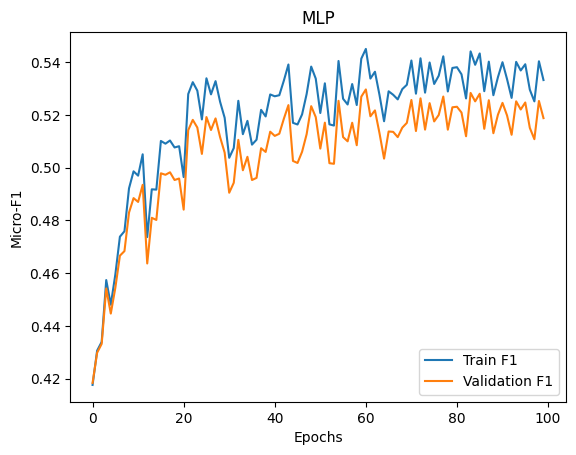

In [ ]:
num_features = train_dataset.num_features   # 50
num_classes = train_dataset.num_classes     # 121
hidden_dim = 256

torch.manual_seed(0)
mlp_model = run(MLP(num_features, hidden_dim, num_classes), "MLP")

**Train the GCN Model**

Epoch 0, Loss: 0.5955, Train F1: 0.419, Val F1: 0.420
Epoch 10, Loss: 0.5248, Train F1: 0.520, Val F1: 0.510
Epoch 20, Loss: 0.5091, Train F1: 0.569, Val F1: 0.556
Epoch 30, Loss: 0.4931, Train F1: 0.562, Val F1: 0.547
Epoch 40, Loss: 0.4774, Train F1: 0.573, Val F1: 0.555
Epoch 50, Loss: 0.4644, Train F1: 0.575, Val F1: 0.555
Epoch 60, Loss: 0.4539, Train F1: 0.586, Val F1: 0.565
Epoch 70, Loss: 0.4559, Train F1: 0.594, Val F1: 0.570
Epoch 80, Loss: 0.4434, Train F1: 0.600, Val F1: 0.576
Epoch 90, Loss: 0.4421, Train F1: 0.601, Val F1: 0.576


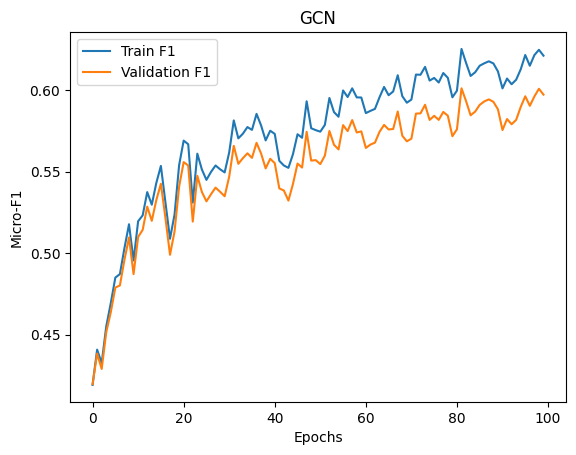

In [ ]:
torch.manual_seed(0)
gcn_model = run(GCN(num_features, hidden_dim, num_classes), "GCN")

**Save the models**

In [ ]:
model_dir = '/tmp/GNN_PPI_demo/saved_models'
os.makedirs(model_dir, exist_ok=True)
torch.save(mlp_model.state_dict(), os.path.join(model_dir, 'mlp_model.pth'))
torch.save(gcn_model.state_dict(), os.path.join(model_dir, 'gcn_model.pth'))

**Compare micro-F1 on unseen test tissues**

In [ ]:
mlp_test_f1 = test(mlp_model, test_loader)
gcn_test_f1 = test(gcn_model, test_loader)

print(f"MLP test micro-F1: {mlp_test_f1:.3f}")
print(f"GCN test micro-F1: {gcn_test_f1:.3f}")

MLP test micro-F1: 0.529
GCN test micro-F1: 0.610


**UMAP Visualizations**

We take each model's hidden layer for the proteins in the test tissues and project it to 2D. Proteins are coloured by the same GO term as in the network plot.

In [ ]:
def get_hidden(model, loader):
    model.eval()
    hidden, y = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            model(batch)                       # fills model.hidden
            hidden.append(model.hidden.cpu())
            y.append(batch.y.cpu())
    return torch.cat(hidden).numpy(), torch.cat(y).numpy()

mlp_hidden, y_test = get_hidden(mlp_model, test_loader)
gcn_hidden, _ = get_hidden(gcn_model, test_loader)

mlp_umap = umap.UMAP(random_state=42).fit_transform(mlp_hidden)
gcn_umap = umap.UMAP(random_state=42).fit_transform(gcn_hidden)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


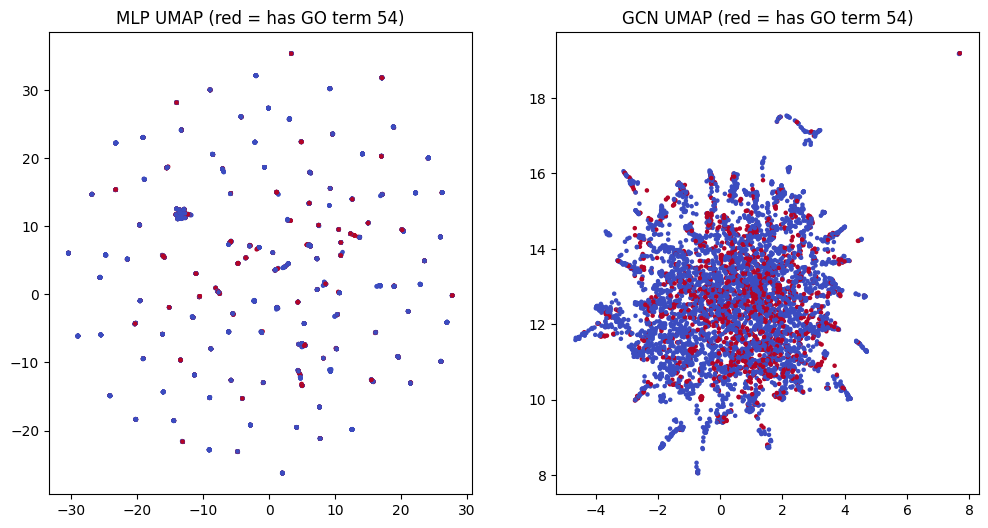

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(mlp_umap[:, 0], mlp_umap[:, 1], c=y_test[:, go_term], cmap="coolwarm", s=5)
plt.title(f"MLP UMAP (red = has GO term {go_term})")

plt.subplot(1, 2, 2)
plt.scatter(gcn_umap[:, 0], gcn_umap[:, 1], c=y_test[:, go_term], cmap="coolwarm", s=5)
plt.title(f"GCN UMAP (red = has GO term {go_term})")

plt.show()

# Bonus: Graph Attention Network (GAT)

A GCN weights every partner by node degree. A **GAT** *learns* how much to listen to each partner (uses attention). On PPI this makes a large difference.

`heads=4` runs 4 attention mechanisms in parallel and concatenates them, so the first layer outputs `hidden_dim * 4` numbers. GAT is slower than GCN, so use a GPU runtime in Colab.

Epoch 0, Loss: 0.5580, Train F1: 0.454, Val F1: 0.451
Epoch 10, Loss: 0.4897, Train F1: 0.549, Val F1: 0.527
Epoch 20, Loss: 0.4758, Train F1: 0.570, Val F1: 0.545
Epoch 30, Loss: 0.4517, Train F1: 0.592, Val F1: 0.568
Epoch 40, Loss: 0.4504, Train F1: 0.593, Val F1: 0.566
Epoch 50, Loss: 0.4409, Train F1: 0.595, Val F1: 0.567
Epoch 60, Loss: 0.4338, Train F1: 0.627, Val F1: 0.601
Epoch 70, Loss: 0.4534, Train F1: 0.629, Val F1: 0.599
Epoch 80, Loss: 0.4370, Train F1: 0.630, Val F1: 0.599
Epoch 90, Loss: 0.4388, Train F1: 0.638, Val F1: 0.607


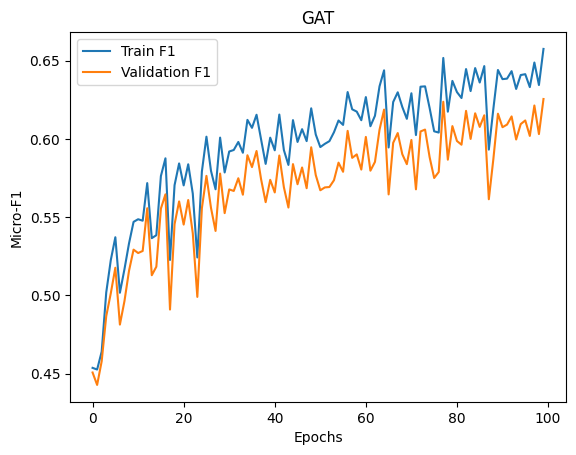

In [ ]:
class GAT(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, heads=4):
        super().__init__()
        self.conv1 = GATConv(input_dim, hidden_dim, heads=heads)
        self.conv2 = GATConv(hidden_dim * heads, output_dim, heads=1)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.elu(self.conv1(x, edge_index))
        self.hidden = x
        x = F.dropout(x, p=0.2, training=self.training)
        return self.conv2(x, edge_index)

torch.manual_seed(0)
gat_model = run(GAT(num_features, hidden_dim, num_classes), "GAT")
gat_test_f1 = test(gat_model, test_loader)

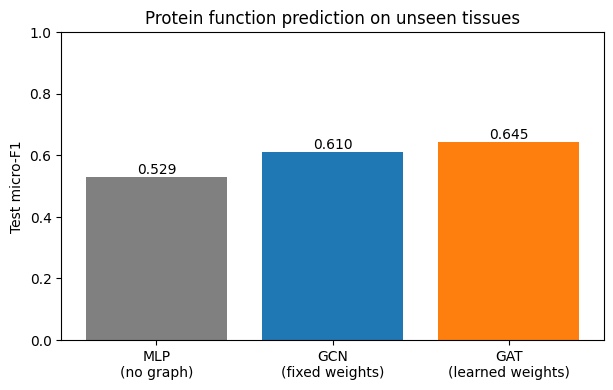

In [ ]:
names = ["MLP\n(no graph)", "GCN\n(fixed weights)", "GAT\n(learned weights)"]
scores = [mlp_test_f1, gcn_test_f1, gat_test_f1]

plt.figure(figsize=(7, 4))
plt.bar(names, scores, color=["gray", "tab:blue", "tab:orange"])
for i, s in enumerate(scores):
    plt.text(i, s + 0.01, f"{s:.3f}", ha="center")
plt.ylabel("Test micro-F1"); plt.ylim(0, 1)
plt.title("Protein function prediction on unseen tissues")
plt.show()

# Takeaways

- **The GCN beats the MLP because interacting proteins share functions.** A protein's partners add information that its own 50 features do not have.
- **Both models are tested on unseen tissues.** GNN weights are shared across all proteins and interactions, so the model works on new graphs.

# Exercises

1. Change `hidden_dim` to 16. Which model suffers most?
2. Add a third `GCNConv` layer. Does looking 3 steps away help?
3. Replace `GCNConv` with `SAGEConv` (from `torch_geometric.nn`), which keeps a protein's own features separate from its partners'. How does it compare?
4. Shuffle the edges of every graph (random partners) and retrain the GCN. What happens to its advantage over the MLP?